# Introduction

This interactive notebook explains how to convert ORD datasets to JSON-LD, how to run queries on the JSON-LDs, and how to visualize chemical reaction data in the JSON-LDs.

Two sample ORD datasets are provided in the test folder. The first, ord_dataset-68cb8b4b2b384e3d85b5b1efae58b203.pb.gz, contains only Suzuki reactions. The second, ord_dataset-00005539a1e04c809a9a78647bea649c.pb.gz, contains multiple types of reactions.

It is recommended that the user enables output scrolling when running the cells because certain cells produce long output text sections.

# Part 1: Converting from ORD to JSON-LD

### Example 1: Convert an entire dataset of reactions from ORD to JSON-LD

Note: This script converts all reactions in the first test ORD dataset (ord_dataset-00005539a1e04c809a9a78647bea649c.pb.gz) to JSON-LD files. If the user wishes to use this code for converting their own dataset, they need to change the following things:

1\. The location where they have cloned the repository (repo_root)  
2\. The path to their ORD dataset (dataset_path)  
3\. The output and log directories (output_dir and log_dir)  

Note: Due to space constraints, the JSON-LDs that are created from running this cell are not in jsonld-examples. However, the user can run this cell to obtain a subfolder in jsonld-examples named all_converted_reactions that contains all the JSON-LDs converted from the ORD dataset.

Note: The conversion may produce a long output; enabling output scrolling is suggested.

In [3]:
from pathlib import Path
import sys
from ord_schema.proto import dataset_pb2

# Change repo_root to the location of your cloned repository
repo_root = Path(
    "/mnt/vstor/CSE_MSE_RXF131/cradle-members/mds3/ops10/Git/rxn-rdf-converter"
).expanduser().resolve()

if not (repo_root / "src" / "dataset_processor.py").is_file():
    raise FileNotFoundError(
        f"Cannot find src/dataset_processor.py under {repo_root}"
    )

sys.path.insert(0, str(repo_root))

from src import dataset_processor

# Replace this path with the path to your ORD dataset
dataset_path = (
    repo_root / "test"
    / "ord_dataset-00005539a1e04c809a9a78647bea649c.pb.gz"
)

# Use the ontology version in the package
owl_onto_path = repo_root / "MDS_Onto.owl"

# Replace these with your output and log directories
output_dir = repo_root / "jsonld-examples/all_converted_reactions"
log_dir = repo_root / "test/example-logs"

for path in (dataset_path, owl_onto_path):
    if not path.is_file():
        raise FileNotFoundError(path)

output_dir.mkdir(parents=True, exist_ok=True)
log_dir.mkdir(parents=True, exist_ok=True)

capture_path = log_dir / "notebook-conversion-output.log"

# Creates the dataset processor
processor = dataset_processor.DatasetProcessor(
    dataset_pb=dataset_pb2,
    dataset_file_path=str(dataset_path),
    owl_onto_file_path=str(owl_onto_path),
    output_directory=str(output_dir),
    error_log_directory=str(log_dir),
    fmt="json-ld",
)

total = len(processor.dataset.reactions)
print(f"Converting all {total} reactions")

reported_exports = []
errors = []

for pb_rxn in processor.dataset.reactions:

    try:
        result = (
            dataset_processor.ReactionKG(pb_rxn, fmt=processor.fmt)
            .generate_reaction()
            .generate_instances(processor.owl_onto)
            .generate_data_graph(processor.dataset_id,
                str(output_dir),
            )
        )

        if result is None:
            errors.append(
                (pb_rxn.reaction_id, "generate_data_graph returned None")
            )
        else:
            reported_exports.append(pb_rxn.reaction_id)
            print("Reported export:", pb_rxn.reaction_id)

    except Exception as exc:
        errors.append((pb_rxn.reaction_id, str(exc)))

# Removes the empty test folder created by the dataset processor's constructor
unused_folder = Path(processor.output_dir)
if unused_folder.is_dir() and not any(unused_folder.iterdir()):
    unused_folder.rmdir()

print(f"Attempted: {total}")
print(f"Reported exports: {len(reported_exports)}")
print(f"Caught errors: {len(errors)}")
print("Detailed output:", capture_path)

# Prints any errors that might have occurred when converting to JSON-LD
for reaction_id, message in errors:
    print(reaction_id, message)


attempting to load_message(/mnt/vstor/CSE_MSE_RXF131/cradle-members/mds3/ops10/Git/rxn-rdf-converter/test/ord_dataset-00005539a1e04c809a9a78647bea649c.pb.gz, dataset_pb.DataSet_
Converting all 750 reactions


[15:36:40] WARNING: Proton(s) added/removed

* Owlready2 * WARNING: ObjectProperty https://cwrusdle.bitbucket.io/files/MDS_Onto/index-en.html#hasFileFormat belongs to more than one entity types: [owl.DatatypeProperty, owl.ObjectProperty]; I'm trying to fix it...
* Owlready2 * WARNING: ObjectProperty https://cwrusdle.bitbucket.io/files/MDS_Onto/index-en.html#hasMinimumLatitude belongs to more than one entity types: [owl.DatatypeProperty, owl.ObjectProperty]; I'm trying to fix it...
* Owlready2 * WARNING: ObjectProperty https://cwrusdle.bitbucket.io/files/MDS_Onto/index-en.html#hasMaximumLatitude belongs to more than one entity types: [owl.DatatypeProperty, owl.ObjectProperty]; I'm trying to fix it...
* Owlready2 * WARNING: ObjectProperty https://cwrusdle.bitbucket.io/files/MDS_Onto/index-en.html#hasMinimumLongitude belongs to more than one entity types: [owl.DatatypeProperty, owl.ObjectProperty]; I'm trying to fix it...
* Owlready2 * WARNING: ObjectProperty https://cwrusdle.bitbucket.io

Reported export: ord-56b1f4bfeebc4b8ab990b9804e798aa7
Reported export: ord-1169cbe9fa064a879ac34b2e524a4e69
Reported export: ord-13992005c22d4673aa802b5e140076e8
Reported export: ord-a36b48917c9942d1a34637511773ee1f
Reported export: ord-5fc624fd97b7430eafbe8dcc049d170b


[15:36:40] WARNING: Proton(s) added/removed

[15:36:40] WARNING: Proton(s) added/removed

[15:36:40] WARNING: Proton(s) added/removed

[15:36:40] WARNING: Proton(s) added/removed

[15:36:40] WARNING: Proton(s) added/removed



Reported export: ord-c34e3f2a76e4462999414a169b276944
Reported export: ord-5853dba403864121802609ae67a6fbe4
Reported export: ord-0c597cbe4940491092243bda6c97b98c
Reported export: ord-b3c4a680709749268aeba07b670223ef
Reported export: ord-fa122fe6774f45c5b7a107c1460052d3


[15:36:40] WARNING: Proton(s) added/removed

[15:36:40] WARNING: Proton(s) added/removed

[15:36:40] WARNING: Proton(s) added/removed

[15:36:40] WARNING: Omitted undefined stereo

[15:36:40] WARNING: Proton(s) added/removed

[15:36:40] WARNING: Omitted undefined stereo

[15:36:40] WARNING: Proton(s) added/removed

[15:36:40] WARNING: Omitted undefined stereo

[15:36:40] WARNING: Omitted undefined stereo



... (32 outputs left out)

Reported export: ord-7ef9bb9d04ab4703a01fe4c2dfba9490
Reported export: ord-05c2bb441c604216aeaf67d50ac253bb
Reported export: ord-e6979ae841a4470289e0e5d2e2b42616
Reported export: ord-d1855bc74886445fbdfc0eab57bed8cb
Reported export: ord-484b31bdd1aa4746881181205ba1de67


[15:36:45] WARNING: Proton(s) added/removed

[15:36:45] WARNING: Proton(s) added/removed

[15:36:45] WARNING: Proton(s) added/removed

[15:36:45] WARNING: Omitted undefined stereo

[15:36:45] WARNING: Charges were rearranged

[15:36:45] WARNING: Charges were rearranged; Omitted undefined stereo



Reported export: ord-6e62fa456f9543438c4d7ca789bf180e
Reported export: ord-3ffbe994308945018df65dd5cc0e0a5b
Reported export: ord-ad4a7da8a91e4c23abc6ab58d6712f3f
Reported export: ord-089e5915f1ae4e9e8fd817c5c0f3bd24
Reported export: ord-d62aaefcc3994ffbb3b7d79fd8d47a34


KeyboardInterrupt: 

### Example 2: Convert part of a dataset of reactions from ORD to JSON-LD

Note: This script converts 10 random reactions from one of the test ORD datasets to JSON-LD files. If the user wishes to use this code for converting part of their own dataset, they need to change the following things:

1\. The location where they have cloned the repository (repo_root)  
2\. The path to their ORD dataset (dataset_path)  
3\. The output and log directories (output_dir and log_dir)  
4\. (Optional) The number of reactions to convert (count)  
5\. (Optional) If they want to generate different random reactions every time they run the cell, they need to remove the line defining the seed (seed = 42) and change the line that determines the random indices to the second option provided below

Note: The JSON-LDs created as a result of running this cell with a seed of 42 are the JSON-LDs in the package's jsonld-examples folder. The JSON-LDs from ord_dataset-00005539a1e04c809a9a78647bea649c.pb.gz are in the subfolder random_converted_reactions, and the JSON-LDs from ord_dataset-68cb8b4b2b384e3d85b5b1efae58b203.pb.gz are in the subfolder random_converted_suzuki.

In [1]:
from pathlib import Path
import sys
from ord_schema.proto import dataset_pb2
import random

# Change repo_root to the location of your cloned repository
repo_root = Path(
    "/mnt/vstor/CSE_MSE_RXF131/cradle-members/mds3/ops10/Git/rxn-rdf-converter"
).expanduser().resolve()

if not (repo_root / "src" / "dataset_processor.py").is_file():
    raise FileNotFoundError(
        f"Cannot find src/dataset_processor.py under {repo_root}"
    )

sys.path.insert(0, str(repo_root))

from src import dataset_processor

# Replace this path with the path to your ORD dataset
dataset_path = (
    repo_root / "test"
    / "ord_dataset-00005539a1e04c809a9a78647bea649c.pb.gz"  # Used to convert 10 random reactions
    #/ "ord_dataset-68cb8b4b2b384e3d85b5b1efae58b203.pb.gz"   # Used to convert 10 random Suzuki reactions
)

# Use the ontology version in the package
owl_onto_path = repo_root / "MDS_Onto.owl"

# Replace these with your output and log directories
output_dir = repo_root / "jsonld-examples/random_converted_reactions" # Used to convert 10 random reactions
#output_dir = repo_root / "jsonld-examples/random_converted_suzuki" # Used to convert 10 random Suzuki reactions
log_dir = repo_root / "test/example-logs"

for path in (dataset_path, owl_onto_path):
    if not path.is_file():
        raise FileNotFoundError(path)

output_dir.mkdir(parents=True, exist_ok=True)
log_dir.mkdir(parents=True, exist_ok=True)

# Replace this with the number of reaction JSON-LDs you want to create
count = 10

# Keep the seed the same for reproducibility; remove the line if you want
# to generate different reaction JSON-LDs every time
seed = 42

# Creates the dataset processor
processor = dataset_processor.DatasetProcessor(
    dataset_pb=dataset_pb2,
    dataset_file_path=str(dataset_path),
    owl_onto_file_path=str(owl_onto_path),
    output_directory=str(output_dir),
    error_log_directory=str(log_dir),
    fmt="json-ld",
)

# Ensures that there are enough reactions in the dataset to generate the number you requested
total = len(processor.dataset.reactions)
if total < count:
    raise ValueError(f"Requested {count} reactions, but dataset has {total}.")

# Delete this line if you don't want to use a seed for generating random reactions
indices = random.Random(seed).sample(range(total), count)

# Use this line instead if you don't want to use a seed for generating random reactions
#indices = random.sample(range(total), count)

reported_exports = []
errors = []

for index in indices:

    pb_rxn = processor.dataset.reactions[index]

    try:
        result = (
            dataset_processor.ReactionKG(pb_rxn, fmt=processor.fmt)
            .generate_reaction()
            .generate_instances(processor.owl_onto)
            .generate_data_graph(
                processor.dataset_id,
                str(output_dir),
            )
        )

        if result is None:
            errors.append(
                (pb_rxn.reaction_id, "generate_data_graph returned None")
            )
        else:
            reported_exports.append(pb_rxn.reaction_id)
            print("Reported export:", pb_rxn.reaction_id)

    except Exception as exc:
        errors.append((pb_rxn.reaction_id, str(exc)))

# Removes the empty test folder created by the dataset processor's constructor
unused_folder = Path(processor.output_dir)
if unused_folder.is_dir() and not any(unused_folder.iterdir()):
    unused_folder.rmdir()

print(f"\nSelected: {count}")
print(f"Reported exports: {len(reported_exports)}")
print(f"Caught errors: {len(errors)}")
print("Output directory:", output_dir)

# Prints any errors that might have occurred when converting to JSON-LD
for reaction_id, message in errors:
    print(reaction_id, message)

attempting to load_message(/mnt/vstor/CSE_MSE_RXF131/cradle-members/mds3/ops10/Git/rxn-rdf-converter/test/ord_dataset-00005539a1e04c809a9a78647bea649c.pb.gz, dataset_pb.DataSet_


* Owlready2 * WARNING: ObjectProperty https://cwrusdle.bitbucket.io/files/MDS_Onto/index-en.html#hasFileFormat belongs to more than one entity types: [owl.DatatypeProperty, owl.ObjectProperty]; I'm trying to fix it...
* Owlready2 * WARNING: ObjectProperty https://cwrusdle.bitbucket.io/files/MDS_Onto/index-en.html#hasMinimumLatitude belongs to more than one entity types: [owl.DatatypeProperty, owl.ObjectProperty]; I'm trying to fix it...
* Owlready2 * WARNING: ObjectProperty https://cwrusdle.bitbucket.io/files/MDS_Onto/index-en.html#hasMaximumLatitude belongs to more than one entity types: [owl.DatatypeProperty, owl.ObjectProperty]; I'm trying to fix it...
* Owlready2 * WARNING: ObjectProperty https://cwrusdle.bitbucket.io/files/MDS_Onto/index-en.html#hasMinimumLongitude belongs to more than one entity types: [owl.DatatypeProperty, owl.ObjectProperty]; I'm trying to fix it...
* Owlready2 * WARNING: ObjectProperty https://cwrusdle.bitbucket.io/files/MDS_Onto/index-en.html#hasMaximumLongi

Reported export: ord-7d6438f5772442a8addd4f9357140a8b
Reported export: ord-63adda83987840e4a77972b9a1ad7b3d
Reported export: ord-f766bf8ef3f8450eb6d323fd10519896
Reported export: ord-69231428717b458492fb802f1da5509b
Reported export: ord-019ad9f92b5c40ecbf5416e8a6461063


[15:21:22] WARNING: Proton(s) added/removed

[15:21:22] WARNING: Proton(s) added/removed

[15:21:22] WARNING: Proton(s) added/removed

[15:21:22] WARNING: Proton(s) added/removed

[15:21:22] WARNING: Proton(s) added/removed



Reported export: ord-f1632d43480c447bab6a25aa93c74396
Reported export: ord-10a49d7456a04dcab0790ed1d012aba2
Reported export: ord-b3b59923db4e4673a6bcde3d5a9c7727
Reported export: ord-411cbd769b2f48f9a0808a7d2919db15
Reported export: ord-805e4c9d19604f5ca8a6f376906a62c5

Selected: 10
Reported exports: 10
Caught errors: 0
Output directory: /mnt/vstor/CSE_MSE_RXF131/cradle-members/mds3/ops10/Git/rxn-rdf-converter/jsonld-examples/random_converted_reactions


[15:21:22] WARNING: Proton(s) added/removed



## Part 2: Run Queries on the JSON-LD Files

### Step 1: Install PyOxiGraph                                                                                                             

Note: If the user has PyOxiGraph installed, they can skip this step

In [2]:
from pathlib import Path
import subprocess
import sys

package_dir = Path.home() / "notebook-packages" / "py310"
package_dir.mkdir(parents=True, exist_ok=True)

subprocess.check_call([
    sys.executable, "-m", "pip", "install",
    "--target", str(package_dir),
    "pyoxigraph",
])

sys.path.insert(0, str(package_dir))

  Using cached pyoxigraph-0.5.13-cp39-abi3-manylinux_2_28_x86_64.whl.metadata (5.7 kB)
Using cached pyoxigraph-0.5.13-cp39-abi3-manylinux_2_28_x86_64.whl (8.2 MB)



[notice] A new release of pip is available: 23.3.2 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip


### Step 2: Load a folder of JSON-LD files using PyOxiGraph

Note: The user should change repo_root to the location where they have cloned the repository

In [16]:
from pyoxigraph import Store, RdfFormat

store = Store()
print("PyOxigraph is ready")

from pathlib import Path

# Change repo_root to the location of your cloned repository
repo_root = Path(
    "/mnt/vstor/CSE_MSE_RXF131/cradle-members/mds3/ops10/Git/rxn-rdf-converter"
).expanduser().resolve()

if not (repo_root / "src" / "dataset_processor.py").is_file():
    raise FileNotFoundError(
        f"Cannot find src/dataset_processor.py under {repo_root}"
    )

sys.path.insert(0, str(repo_root))

# Load a folder of JSON-LD files - change the path to your path
folder = repo_root / "jsonld-examples"

files = sorted(
    path for path in folder.rglob("*")
    if path.is_file()
    and path.suffix.lower() in {".jsonld", ".json_ld", ".json"}
)

if not files:
    raise FileNotFoundError(f"No JSON-LD files found in {folder}")

# Start fresh so rerunning this cell doesn't accumulate prior loads
store = Store()

for path in files:
    store.load(path=str(path), format=RdfFormat.JSON_LD)

    #path = next(
    #p for p in files
    #if "1c40487a68354d528624c40f8a926628" in p.name
    #)

    #check_store = Store()
    #check_store.load(path=str(path), format=RdfFormat.JSON_LD)

    #print("File:", path)
    #print("Statements:", len(check_store))

    #for statement in check_store:
    #    print(statement)

print(f"Loaded {len(files)} files containing {len(store)} RDF statements")

PyOxigraph is ready
Loaded 366 files containing 5998 RDF statements


### Step 3: Write and run queries on the JSON-LD files

##### Example 1: Select Reactions and Reaction Types

In [17]:
import pandas as pd

import json
from urllib.parse import quote
from pyoxigraph import Store, RdfFormat

# Following code can be used to repair the issue for one of the files
"""
# Select the file you just shared
path = next(
    p for p in files
    if "b5d88ffb8907466c88de58133b09a33e" in p.name
)

data = json.loads(path.read_text(encoding="utf-8"))

def repair_ids(value):
    if isinstance(value, dict):
        for key, item in value.items():
            if (
                key == "@id"
                and isinstance(item, str)
                and item.startswith(("http://", "https://"))
            ):
                # Preserve the first # as the fragment separator;
                # encode additional # characters and spaces.
                base, separator, fragment = item.partition("#")
                base = base.replace(" ", "%20")
                value[key] = base + separator + quote(
                    fragment,
                    safe="/?:@!$&'()*+,;=-._~%",
                )
            else:
                repair_ids(item)
    elif isinstance(value, list):
        for item in value:
            repair_ids(item)

original_store = Store()
original_store.load(path=str(path), format=RdfFormat.JSON_LD)

repair_ids(data)

repaired_store = Store()
repaired_store.load(
    input=json.dumps(data),
    format=RdfFormat.JSON_LD,
)

print("Original statements:", len(original_store))
print("After identifier repair:", len(repaired_store))
"""

query = """
PREFIX mds: <https://cwrusdle.bitbucket.io/files/MDS_Onto/index-en.html#>
PREFIX cco: <https://www.commoncoreontologies.org/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT DISTINCT  ?reaction ?reactionType
WHERE {
  # 1. Find all Chemical Reactions
  ?reaction rdf:type mds:ChemicalReaction .

  # 2. find a Reaction Type string
  ?typeResource rdf:type mds:ReactionType ;
                cco:ont00001916 ?reaction ;
                cco:ont00001765 ?reactionType .
}
ORDER BY ?reactionType
"""

# Get the PyOxigraph raw result
# TO DO: Remove below line
#results = repaired_store.query(query)
results = store.query(query)
columns = [variable.value for variable in results.variables]

# Create a DataFrame of the result
# This code can be used to create a DataFrame with the results of any select query
df = pd.DataFrame(
    [
        [
            row[column].value if row[column] is not None else None
            for column in columns
        ]
        for row in results
    ],
    columns=columns,
)

display(df)

,reaction,reactionType


##### Example 2: Select Reaction Types and Counts

In [5]:
import pandas as pd

query = """
PREFIX mds: <https://cwrusdle.bitbucket.io/files/MDS_Onto/index-en.html#>
PREFIX cco: <https://www.commoncoreontologies.org/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT ?reactionType (COUNT(?reaction) AS ?reactionCount)
WHERE {
  # 1. Find all Chemical Reactions
  ?reaction rdf:type mds:ChemicalReaction .

  # 2. find a Reaction Type string
  ?typeResource rdf:type mds:ReactionType ;
                cco:ont00001916 ?reaction ;
                cco:ont00001765 ?reactionType .
}
GROUP BY ?reactionType
ORDER BY DESC(?reactionCount)
"""

# Get the PyOxigraph raw result
results = store.query(query)
columns = [variable.value for variable in results.variables]

# Create a DataFrame of the result
# This code can be used to create a DataFrame with the results of any select query
df = pd.DataFrame(
    [
        [
            row[column].value if row[column] is not None else None
            for column in columns
        ]
        for row in results
    ],
    columns=columns,
)

display(df)

,reactionType,reactionCount


##### Example 3: Get the number of instances of each class

In [8]:
import pandas as pd

query = """
PREFIX mds: <https://cwrusdle.bitbucket.io/files/MDS_Onto/index-en.html#>
PREFIX cco: <https://www.commoncoreontologies.org/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT ?class (COUNT(?instance) AS ?instancecount)

WHERE {
    ?instance a ?class .
}

GROUP BY ?class
ORDER BY DESC(?instancecount)
"""

# Get the PyOxigraph raw result
results = store.query(query)
columns = [variable.value for variable in results.variables]

# Create a DataFrame of the result
# This code can be used to create a DataFrame with the results of any select query
df = pd.DataFrame(
    [
        [
            row[column].value if row[column] is not None else None
            for column in columns
        ]
        for row in results
    ],
    columns=columns,
)

display(df)

,class,instancecount
0,https://www.commoncoreontologies.org/ont00000808,24
1,https://www.commoncoreontologies.org/ont00000267,23
2,https://www.commoncoreontologies.org/ont00001160,21
3,https://www.commoncoreontologies.org/ont00000581,10


##### Example 4: Get the the total number of nodes on the graph

In [5]:
query = """
PREFIX mds: <https://cwrusdle.bitbucket.io/files/MDS_Onto/index-en.html#>
PREFIX cco: <https://www.commoncoreontologies.org/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
PREFIX obo: <http://purl.obolibrary.org/obo/>

SELECT (COUNT(DISTINCT ?node) AS ?totalUniqueNodes)
WHERE {
  {
    # Pattern 1: Find all nodes that are subjects
    ?node ?p ?o .
  }
  UNION
  {
    # Pattern 2: Find all nodes that are objects
    ?s ?p ?node .
  }
}
"""

# Get the PyOxigraph raw result
results = store.query(query)
columns = [variable.value for variable in results.variables]

# Create a DataFrame of the result
# This code can be used to create a DataFrame with the results of any select query
df = pd.DataFrame(
    [
        [
            row[column].value if row[column] is not None else None
            for column in columns
        ]
        for row in results
    ],
    columns=columns,
)

display(df)

,totalUniqueNodes
0,4853


##### Example 5: Find all reactions with a given "ReactionType" and their desired products. 

Note: This exact query can be used to find ALL products (not just the desired product) by removing line 63 ("mds:isDesiredProduct true .") and replacing the semicolon at the end of line 62 ("?product a mds:Product ;") with a period.

In [11]:
import pandas as pd

query = """
PREFIX mds: <https://cwrusdle.bitbucket.io/files/MDS_Onto/index-en.html#>
PREFIX cco: <https://www.commoncoreontologies.org/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
PREFIX obo: <http://purl.obolibrary.org/obo/>

SELECT DISTINCT ?reaction ?reactionType ?component ?smiles ?reactionRole ?amountValue
	?amountUnit ?tempValue ?tempUnit ?productSmiles ?productPercent ?productUnit ?procedureDetails
WHERE {
  # 1. Find all Chemical Reactions
    ?reaction rdf:type mds:ChemicalReaction ;
              cco:ont00001777 ?inputAddition ; # has process part
    	      cco:ont00001986 ?product ;       # has output
              mds:procedureDetails ?procedureDetails.
    ?inputAddition a mds:InputAddition .

  # 2. find a Reaction Type string
    ?typeResource rdf:type mds:ReactionType ;
                  cco:ont00001916 ?reaction ;  # designates
                  cco:ont00001765 ?reactionType . # has text value

    # 3. find all components
    ?component a mds:Component ;
               cco:ont00001841 ?inputAddition . # is input of

  # 4. find the amount value and unit of each component
    ?amountResource obo:BFO_0000197 ?component ;    # inheres in
                    cco:ont00001769 ?amountValue ;  # has decimal value
                    cco:ont00001863 ?amountUnit .   # uses measurement unit

  # 5. find the smiles string for each component.
    ?smilesResource a mds:SMILES ;
                    cco:ont00001916 ?component ; # designates
                    cco:ont00001765 ?smiles . # has text value
  # 6. find the correct reaction environment with the temperature
    ?reactionEnvironment a mds:ReactionEnvironment;
                         obo:BFO_0000183 ?reaction ;     # environs
                         obo:BFO_0000196 ?reactionTemp.  # bearer of

  # 7. get reaction role and filter for only specific types
    ?reactionRole obo:BFO_0000197 ?component ;
    	          a ?roleType.

  # 8. find the reaction temperature
    ?reactionTemp a mds:ReactionTemperature .

    ?temperaturemeasurement a mds:AnalyticalResult;
                            cco:ont00001808 ?reactionTemp ; # is about
                            cco:ont00001769 ?tempValue;     # has decimal value
                            cco:ont00001863 ?tempUnit.      # uses measurement unit

  # 9. find the reaction product
    ?productMeasurement a mds:AnalyticalResult ;
                        cco:ont00001808 ?product ;         # is about
                        cco:ont00001769 ?productPercent ;  # has decimal value
                        cco:ont00001863 ?productUnit .     # uses measurement unit

    ?product a mds:Product ;
             mds:isDesiredProduct true .

    ?smilesproduct rdf:type mds:SMILES ;
                   cco:ont00001916 ?product ;
                   cco:ont00001765 ?productSmiles .

}
ORDER BY ?reactionType
"""

# Get the PyOxigraph raw result
results = store.query(query)
columns = [variable.value for variable in results.variables]

# Create a DataFrame of the result
# This code can be used to create a DataFrame with the results of any select query
df = pd.DataFrame(
    [
        [
            row[column].value if row[column] is not None else None
            for column in columns
        ]
        for row in results
    ],
    columns=columns,
)

display(df)

,reaction,reactionType,component,smiles,reactionRole,amountValue,amountUnit,tempValue,tempUnit,productSmiles,productPercent,productUnit,procedureDetails


# Part 3: Use NetworkX to Visualize Reactions

### Step 1: Install NetworkX                                                                                                                

Note: If the user has NetworkX installed, they can skip this step

In [12]:
from pathlib import Path
import subprocess
import sys

package_dir = Path.home() / "notebook-packages" / "py310"

subprocess.check_call([
    sys.executable, "-m", "pip", "install",
    "--target", str(package_dir),
    "networkx", "matplotlib",
])

if str(package_dir) not in sys.path:
    sys.path.insert(0, str(package_dir))

  Using cached networkx-3.4.2-py3-none-any.whl.metadata (6.3 kB)
  Using cached matplotlib-3.10.9-cp310-cp310-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (52 kB)
  Using cached contourpy-1.3.2-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.65.0-cp310-cp310-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (125 kB)
  Using cached kiwisolver-1.5.1-cp310-cp310-manylinux_2_12_x86_64.manylinux2010_x86_64.whl.metadata (5.2 kB)
  Using cached numpy-2.2.6-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (62 kB)
  Using cached packaging-26.3-py3-none-any.whl.metadata (3.5 kB)
  Using cached pillow-12.3.0-cp310-cp310-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached python_dateutil-3.0.0-py2.py3-none-any.whl.metadata (8.2 kB)
  Using cached six-

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
nrel-rex 0.2.85 requires h5pyd>=0.7.0, which is not installed.
albumentations 1.3.1 requires opencv-python-headless>=4.1.1, which is not installed.
arviz 0.18.0 requires h5netcdf>=1.0.2, which is not installed.
arviz 0.18.0 requires xarray-einstats>=0.3, which is not installed.
basemap 1.3.8 requires basemap-data<1.4,>=1.3.2, which is not installed.
cdlib 0.3.0 requires angelcommunity, which is not installed.
cdlib 0.3.0 requires bimlpa, which is not installed.
cdlib 0.3.0 requires demon, which is not installed.
cdlib 0.3.0 requires dynetx, which is not installed.
cdlib 0.3.0 requires eva-lcd, which is not installed.
cdlib 0.3.0 requires markov-clustering, which is not installed.
cdlib 0.3.0 requires nf1, which is not installed.
cdlib 0.3.0 requires pulp, which is not installed.
cdlib 0.3.0 requires python-igraph>

### Step 2: Create a query that returns a reaction to visualize, and get the reaction's incoming and outgoing relationships

Note: This and the next step assume that a JSON-LD file has been loaded in using PyOxigraph (the code under the section "Load a JSON-LD File Using PyOxiGraph")

In [10]:
import networkx as nx
import matplotlib.pyplot as plt

# Pick one reaction
query = """
PREFIX mds: <https://cwrusdle.bitbucket.io/mds/>
PREFIX cco: <https://www.commoncoreontologies.org/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT DISTINCT ?reaction
WHERE {
  # 1. Find all Chemical Reactions
  ?reaction rdf:type mds:ChemicalReaction .

  # 2. find a Reaction Type string
  ?typeResource rdf:type mds:ReactionType ;
                cco:ont00001916 ?reaction ;
                cco:ont00001765 ?reactionType .
}
ORDER BY ?reactionType
LIMIT 1
"""

reaction_rows = list(store.query(query))
if not reaction_rows:
    raise ValueError("No ChemicalReaction found in the store.")

reaction = reaction_rows[0]["reaction"]

# Get incoming and outgoing relationships for that reaction
connections_query = f"""
SELECT DISTINCT ?s ?p ?o
WHERE {{
    {{ BIND({str(reaction)} AS ?s) ?s ?p ?o . }}
    UNION
    {{ ?s ?p ?o . FILTER(?o = {str(reaction)}) }}
}}
"""

### Step 3: Use NetworkX to visualize the reaction

Note: Colors are determined by the type of node

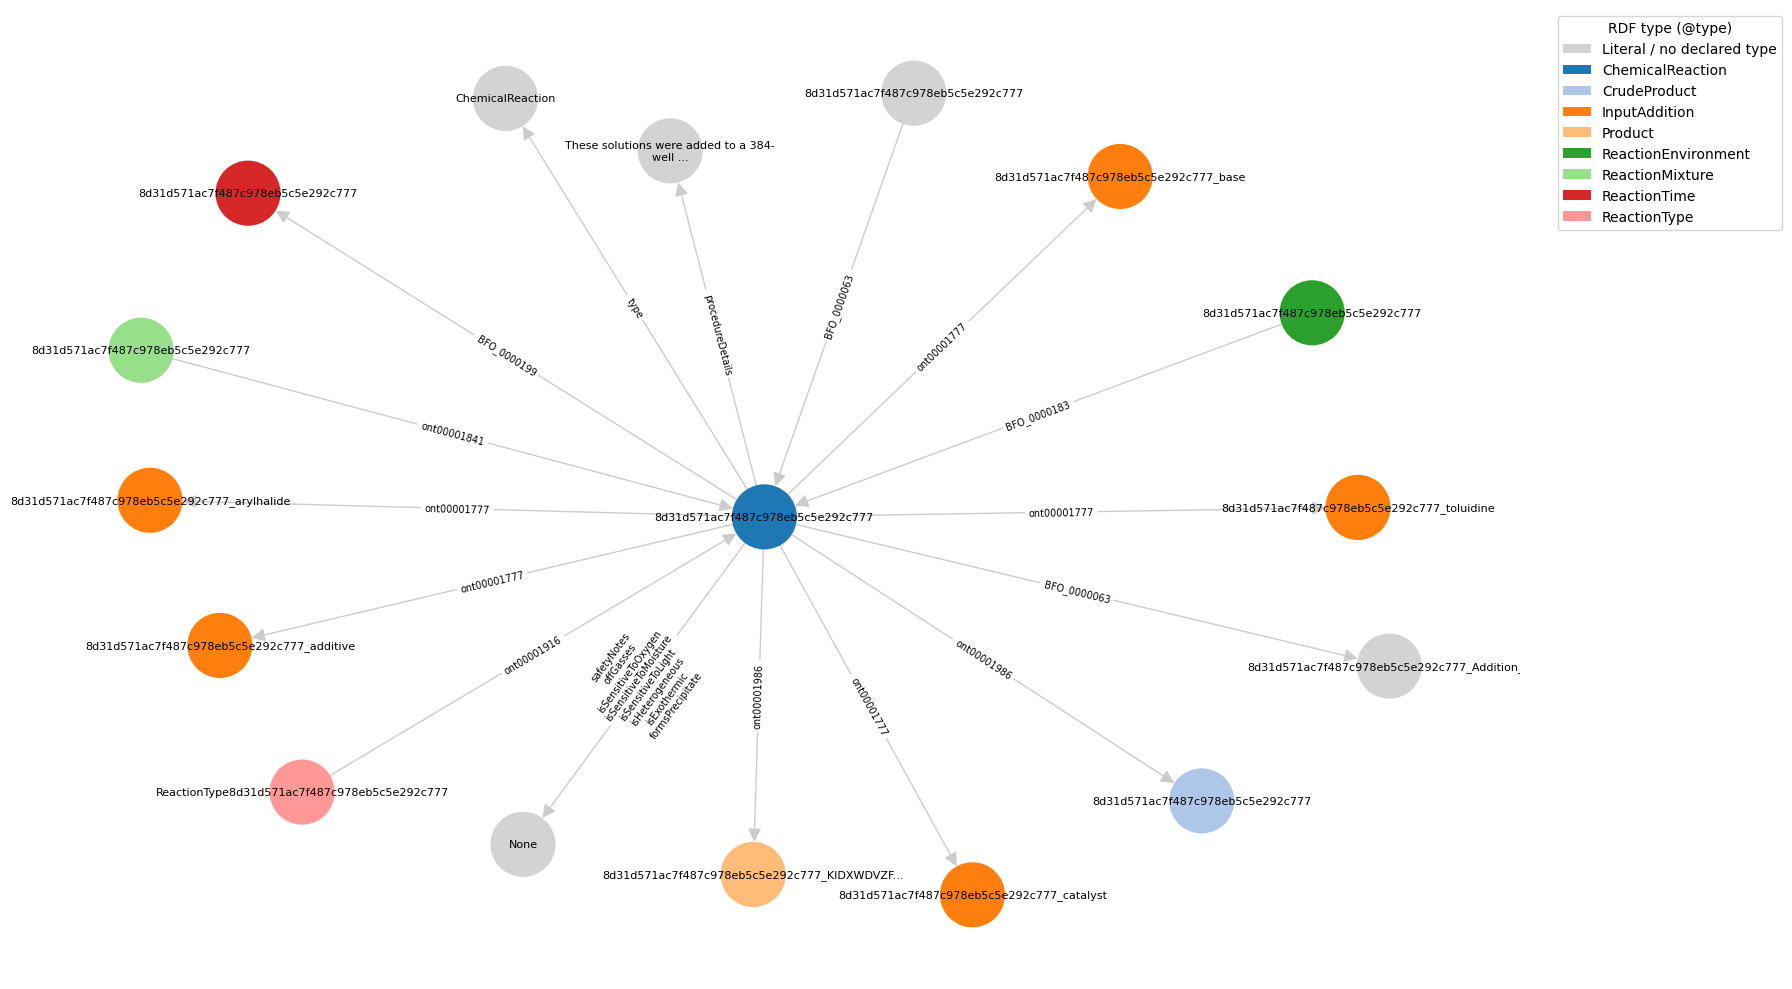

In [18]:
from collections import defaultdict
from matplotlib.patches import Patch

def short_label(term):
    text = term.value
    if text.startswith(("http://", "https://")):
        text = text.rstrip("/").rsplit("#", 1)[-1].rsplit("/", 1)[-1]
    return text if len(text) <= 45 else text[:42] + "..."

G = nx.DiGraph()

for row in store.query(connections_query):
    s, p, o = row["s"], row["p"], row["o"]
    source, target = str(s), str(o)

    G.add_node(source, label=short_label(s))
    G.add_node(target, label=short_label(o))

    label = short_label(p)
    if G.has_edge(source, target):
        G[source][target]["label"] += "\n" + label
    else:
        G.add_edge(source, target, label=label)

# Read types from the full store, including types not shown in this graph
types_by_node = defaultdict(set)
type_labels = {}

type_query = """
SELECT DISTINCT ?node ?type
WHERE {
    ?node a ?type .
}
"""

for row in store.query(type_query):
    node_id = str(row["node"])
    type_id = str(row["type"])

    types_by_node[node_id].add(type_id)
    type_labels[type_id] = short_label(row["type"])

# Group nodes by their type(s).
# Nodes with multiple types get a distinct combined category.
node_categories = {
    node: tuple(sorted(types_by_node.get(node, set())))
    for node in G.nodes
}

categories = sorted(set(node_categories.values()))
typed_categories = [category for category in categories if category]

cmap = plt.get_cmap("tab20")
category_colors = {
    category: cmap(index % cmap.N)
    for index, category in enumerate(typed_categories)
}

# Literal values and nodes without a declared type are gray
category_colors[()] = "lightgray"

colors = [
    category_colors[node_categories[node]]
    for node in G.nodes
]

positions = nx.spring_layout(G, seed=42, k=1.5)

fig, ax = plt.subplots(figsize=(18, 10))

nx.draw_networkx(
    G,
    positions,
    labels=nx.get_node_attributes(G, "label"),
    node_color=colors,
    node_size=2200,
    font_size=8,
    arrows=True,
    arrowsize=20,
    ax=ax,
    edge_color="#CCCCCC",
    font_color="#000000",
    linewidths=0,
)

nx.draw_networkx_edge_labels(
    G,
    positions,
    edge_labels=nx.get_edge_attributes(G, "label"),
    font_size=7,
    ax=ax,
)

# Explain the colors in a legend
legend_items = [
    Patch(
        facecolor=category_colors[category],
        label=(
            " + ".join(type_labels[type_id] for type_id in category)
            if category
            else "Literal / no declared type"
        ),
    )
    for category in categories
]

ax.legend(
    handles=legend_items,
    title="RDF type (@type)",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
)

ax.axis("off")
plt.tight_layout()
plt.show()